# Cu bulk (FCC): band structure from FHI-aims' real-space H/S

Reads the real `output_rs_matrices` dump (`rs_indices.out`, `rs_hamiltonian.out`,
`rs_overlap.out`) of a converged FHI-aims FCC-Cu calculation (1 atom, 1 species,
31 basis orbitals) with `sisl.io.fhiaims.rsSileFHIaims`, builds a `sisl.Hamiltonian`,
and plots the band structure along the standard FCC high-symmetry path.

This is a sanity check, not a cross-check against FHI-aims' own output (this
particular run has no `output band` dump) -- see the SrTiO3 notebook for a
direct, quantitative comparison against FHI-aims' own band structure.

In [1]:
%matplotlib inline
import re
import matplotlib.pyplot as plt
import numpy as np
import sisl
from sisl.io.fhiaims.rs import rsSileFHIaims

DATA = "../cu_bulk_fcc/"


In [2]:
def read_fermi_level(aims_out):
    pat = re.compile(r"Chemical potential \(Fermi level\):\s*([-\d.]+) eV")
    Ef = None
    for line in open(aims_out):
        m = pat.search(line)
        if m:
            Ef = float(m.group(1))
    return Ef

H = rsSileFHIaims(DATA + "rs_indices.out").read_hamiltonian()
Ef = read_fermi_level(DATA + "aims.out")
print(f"{H.geometry.na} atom, {H.geometry.no} orbitals, Ef = {Ef:.4f} eV")


1 atom, 31 orbitals, Ef = -5.3007 eV


Standard FCC high-symmetry points, in reduced coordinates of the primitive
reciprocal lattice vectors: Gamma-X-W-K-Gamma-L.

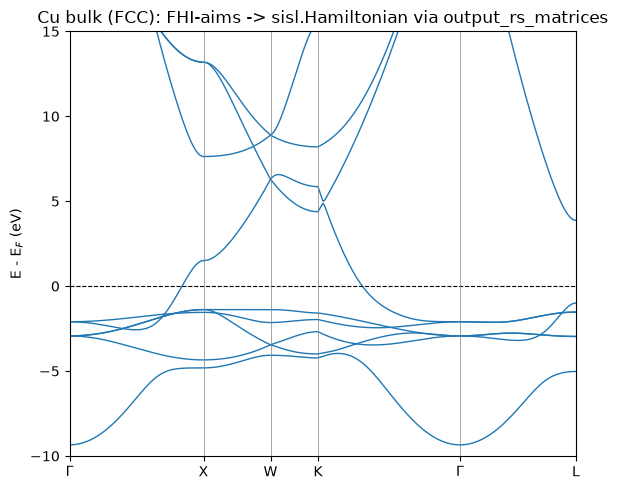

In [3]:
G, X, W, K, L = [0, 0, 0], [0, .5, .5], [.25, .75, .5], [.375, .75, .375], [.5, .5, .5]
bs = sisl.BandStructure(H, [G, X, W, K, G, L], 301,
                         [r"$\Gamma$", "X", "W", "K", r"$\Gamma$", "L"])
lk, kt, kl = bs.lineark(True)
eigs = np.asarray(bs.apply.array.eigh()) - Ef

fig, ax = plt.subplots(figsize=(6, 5))
for n in range(eigs.shape[1]):
    ax.plot(lk, eigs[:, n], color="tab:blue", lw=1)
ax.axhline(0.0, color="k", ls="--", lw=0.8)
for t in kt:
    ax.axvline(t, color="gray", lw=0.5)
ax.set_xticks(kt)
ax.set_xticklabels(kl)
ax.set_ylabel("E - E$_F$ (eV)")
ax.set_ylim(-10, 15)
ax.set_xlim(lk[0], lk[-1])
ax.set_title("Cu bulk (FCC): FHI-aims -> sisl.Hamiltonian via output_rs_matrices")
fig.tight_layout()
plt.show()


The narrow, nearly-flat bands ~2-5 eV below E_F are the Cu 3d manifold, with the
broad, free-electron-like 4s band crossing them and E_F -- the textbook Cu band
structure, reproduced entirely from FHI-aims' real-space H/S dump.